In [2]:
import pandas as pd

In [8]:
# Load the dataset
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/reviews.csv', engine='python', on_bad_lines='skip')

# Show the first 5 rows
df.head()

,id,asin,url,body,date,title,images,videos,stars,user_id,variation,found_helpful,verified_purchase
0,RVAV3SWVU0O0W,B085DVHQ57,https://www.amazon.com/gp/customer-reviews/RVA...,Whenever asked by recent high school grads wha...,Sat Jul 05 2025,"My go-to water bottle, I take it everywhere I go",[],[],5,amzn1.account.AEPH7VYTQBYH6UW7INYUMMYNSBEA,Size: 24 Ounces Color: Shy Marshmallow,5,1.0
1,R1VVZ8F6WC4CWP,B085DVHQ57,https://www.amazon.com/gp/customer-reviews/R1V...,I bought the Owala FreeSip Insulated Stainless...,Fri Jun 06 2025,Perfect for Kids and Adults — My 12-Year-Old L...,[],[],5,amzn1.account.AE3WFQSNFH7ARSXPHUQZQV6CQ2TA,Size: 24 Ounces Color: Shy Marshmallow,47,1.0
2,R1N1YR132OT1B4,B085DVHQ57,https://www.amazon.com/gp/customer-reviews/R1N...,Can't say enough about this water bottle. I tr...,Thu Jun 26 2025,Not Even Close - Best H20 Bottle on the Market,[],[],5,amzn1.account.AE2PKPB3WT4L6WKMFUQHMA5ZMD3A,Size: 32 Ounces Color: Foggy Tide,25,1.0
3,R2NVM73BPETXF8,B085DVHQ57,https://www.amazon.com/gp/customer-reviews/R2N...,I've had this for over a year now and it's def...,Fri Jun 13 2025,Best water bottle,[],[],5,amzn1.account.AG4LH3S3WIYF4NQTZYUT2XHVAPMQ,Size: 24 Ounces Color: Foggy Tide,16,1.0
4,R20Q2RHQ3NGXB,B085DVHQ57,https://www.amazon.com/gp/customer-reviews/R20...,This is our third Owala Kids FreeSip bottle an...,Tue Jul 01 2025,"Great water bottle, easy clean",[],[],5,amzn1.account.AGZ43YBXQ6P5U4TGTIBOCN3SJ5GQ,Size: 16 Ounces Color: Mint Chocolate,3,1.0


In [9]:
# 1. Drop rows where the review text and stars are missing.
df_clean = df.dropna(subset=['body', 'stars'])

# 2. Total reviews and average rating
total_reviews = len(df_clean)
avg_rating = df_clean['stars'].mean()

print(f"Total Reviews Analyzed: {total_reviews}")
print(f"Average Rating: {avg_rating:.2f} / 5.0\n")

# 3. Rating distribution (The GROUP BY equivalent)
print("Rating Distribution:")
print(df_clean['stars'].value_counts().sort_index())

# 4. Filter for Low-Rated reviews (1 or 2 stars)
low_rated = df_clean[df_clean['stars'] <= 2]
print(f"\nNumber of Low-Rated Reviews (1-2 stars): {len(low_rated)}")

Total Reviews Analyzed: 255714
Average Rating: 4.64 / 5.0

Rating Distribution:
stars
1      3059
2      3349
3     12819
4     43520
5    192967
Name: count, dtype: int64

Number of Low-Rated Reviews (1-2 stars): 6408


In [10]:
import matplotlib.pyplot as plt

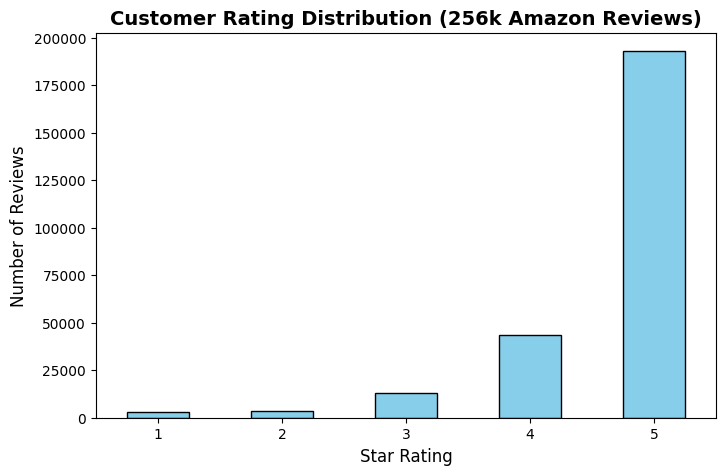

In [11]:
# Create the plot
plt.figure(figsize=(8, 5))
df_clean['stars'].value_counts().sort_index().plot(kind='bar', color='skyblue', edgecolor='black')

# Add titles and labels
plt.title('Customer Rating Distribution (256k Amazon Reviews)', fontsize=14, fontweight='bold')
plt.xlabel('Star Rating', fontsize=12)
plt.ylabel('Number of Reviews', fontsize=12)

# Rotate the numbers on the x-axis so they are flat
plt.xticks(rotation=0)

# Show the plot
plt.show()